# Fase 4 · CNN desde cero: tabla de experimentos y clasificador de especie

Analiza los resultados que produce `04_modelado/entrenar_cnn.py` (no reentrena nada). Sigue la actividad
`CORTE 3/02-CNN_resuelto` del curso: una **tabla de experimentos** que cambia una cosa a la vez y se mide en validación.

**Reglas que se cumplen:**
* Solo `train` y `val`: **el test no se usa**. La parada temprana usa la pérdida de validación, así que la validación queda
  **ligeramente optimista** y no sustituye al test ni a las fotos propias.
* La tarea es **Buena vs. Mala** (la clase *Regular* aún no existe) con etiquetas débiles de Kaggle.
* Se compara siempre con la línea base de ML tradicional y con el control **"solo borde"** (E10): una CNN que ve únicamente
  el marco de la imagen mide cuánto del rendimiento puede ser fondo.
* Una diferencia entre dos experimentos **no es concluyente** si es menor que 2 errores estándar de la diferencia.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

REPO = Path.cwd().parent if Path.cwd().name == "04_modelado" else Path.cwd()
PROC = REPO / "data" / "processed" / "cnn_runs"
FIG = REPO / "04_modelado" / "figuras"
FIG.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["savefig.bbox"] = "tight"


def guardar(fig, nombre):
    fig.savefig(FIG / f"{nombre}.pdf")


res = pd.read_csv(REPO / "04_modelado" / "resultados_cnn_calidad.csv")
clasicos = pd.read_csv(REPO / "04_modelado" / "resultados_modelos_clasicos.csv").set_index("modelo")
print(f"{len(res)} experimentos de calidad; modelos clásicos de referencia: {list(clasicos.index)}")

10 experimentos de calidad; modelos clásicos de referencia: ['baseline_mayoritaria', 'logreg', 'svm_rbf', 'random_forest']


## 1. Tabla de experimentos (calidad, Buena vs. Mala, en validación)

In [2]:
cols = ["id", "descripcion", "head", "filtros", "dropout", "l2", "aumento", "lr", "size", "parametros", "epocas_corridas",
        "mejor_epoca", "F1_train", "F1_val", "brecha_F1", "EE_val", "kappa_val", "s_por_epoca"]
tabla = res[cols].copy()
tabla["parametros"] = tabla["parametros"].map("{:,}".format)
tabla.round(3)

,id,descripcion,head,filtros,dropout,l2,aumento,lr,size,parametros,epocas_corridas,mejor_epoca,F1_train,F1_val,brecha_F1,EE_val,kappa_val,s_por_epoca
0,E1,"Guía del curso: Flatten, Dense 64, sin regular...",flatten,32-64-128,0.0,0.0,False,0.001,96,"1,273,090",6,3,0.977,0.922,0.056,0.005,0.844,37.5
1,E2,E1 + Dropout 0.5,flatten,32-64-128,0.5,0.0,False,0.001,96,"1,273,090",5,2,0.947,0.906,0.041,0.006,0.812,33.7
2,E3,GAP + Dropout 0.5,gap,32-64-128,0.5,0.0,False,0.001,96,"110,018",6,3,0.930,0.913,0.017,0.005,0.827,32.5
3,E4,Flatten + Dropout 0.5 + aumento de datos,flatten,32-64-128,0.5,0.0,True,0.001,96,"2,452,930",9,6,0.967,0.938,0.028,0.005,0.877,41.1
4,E5,GAP + Dropout 0.5 + aumento de datos,gap,32-64-128,0.5,0.0,True,0.001,96,"110,018",15,12,0.968,0.929,0.038,0.005,0.858,34.6
5,E6,E5 + L2 1e-4,gap,32-64-128,0.5,0.0,True,0.001,96,"110,018",18,15,0.960,0.926,0.033,0.005,0.853,35.9
6,E7,E5 con menos filtros (16-32-64),gap,16-32-64,0.5,0.0,True,0.001,96,"32,162",18,15,0.957,0.908,0.050,0.005,0.815,14.3
7,E8,E5 con tasa de aprendizaje 3e-4,gap,32-64-128,0.5,0.0,True,0.000,96,"110,018",15,12,0.935,0.909,0.027,0.005,0.818,33.2
8,E9,E5 a 128 px,gap,32-64-128,0.5,0.0,True,0.001,128,"110,018",15,12,0.960,0.921,0.039,0.005,0.842,59.4
9,E10,CONTROL solo borde: E5 con el centro enmascarado,gap,32-64-128,0.5,0.0,True,0.001,96,"110,018",14,11,0.907,0.871,0.036,0.006,0.744,33.0


## 2. Curvas de aprendizaje

Pérdida de entrenamiento y de validación por época. Una brecha que se abre indica sobreajuste; la parada temprana
restaura los pesos de la mejor época de validación.

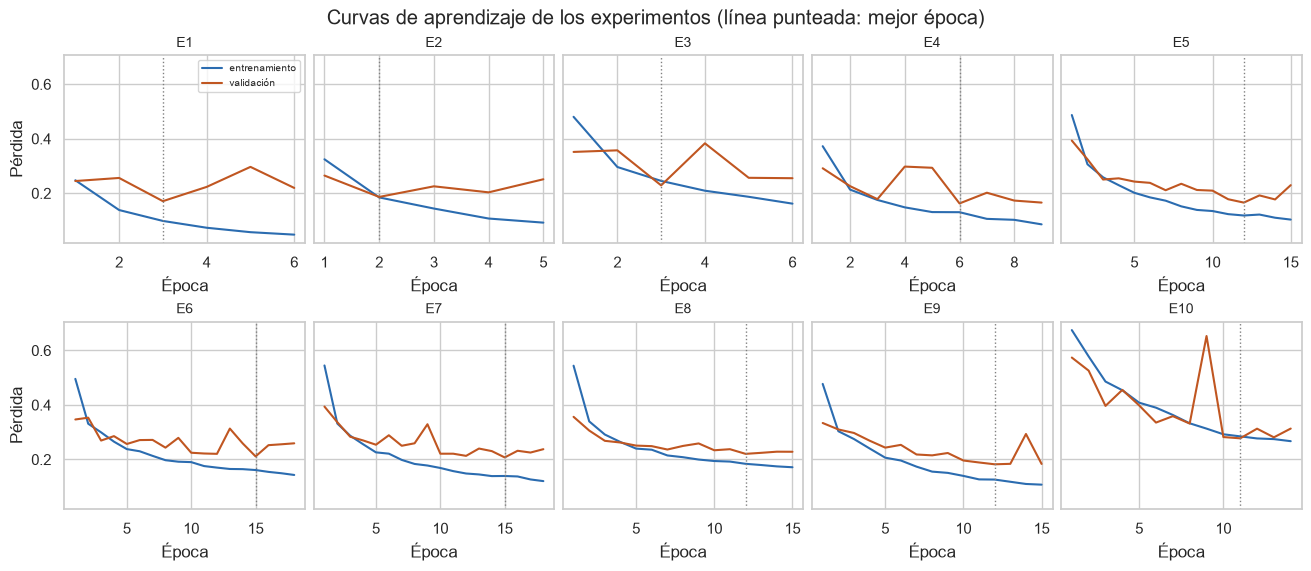

In [3]:
hist = {}
for ident in res["id"]:
    ruta = PROC / f"calidad_{ident}.json"
    if ruta.exists():
        hist[ident] = json.loads(ruta.read_text(encoding="utf-8"))["historia"]
n = len(hist)
fig, axes = plt.subplots(2, (n + 1) // 2, figsize=(2.6 * ((n + 1) // 2), 5.6), sharey=True, constrained_layout=True)
for ax, (ident, h) in zip(axes.ravel(), hist.items()):
    ep = np.arange(1, len(h["loss"]) + 1)
    ax.plot(ep, h["loss"], label="entrenamiento", color="#2B6CB0")
    ax.plot(ep, h["val_loss"], label="validación", color="#C05621")
    ax.axvline(int(res.set_index("id").loc[ident, "mejor_epoca"]), color="gray", ls=":", lw=1)
    ax.set_title(ident, fontsize=10); ax.set_xlabel("Época")
for ax in axes[:, 0]:
    ax.set_ylabel("Pérdida")
axes.ravel()[0].legend(fontsize=7)
for ax in axes.ravel()[n:]:
    ax.axis("off")
fig.suptitle("Curvas de aprendizaje de los experimentos (línea punteada: mejor época)")
guardar(fig, "cnn_curvas_aprendizaje")
plt.show()

## 3. Comparación con ML tradicional y con el control de solo borde

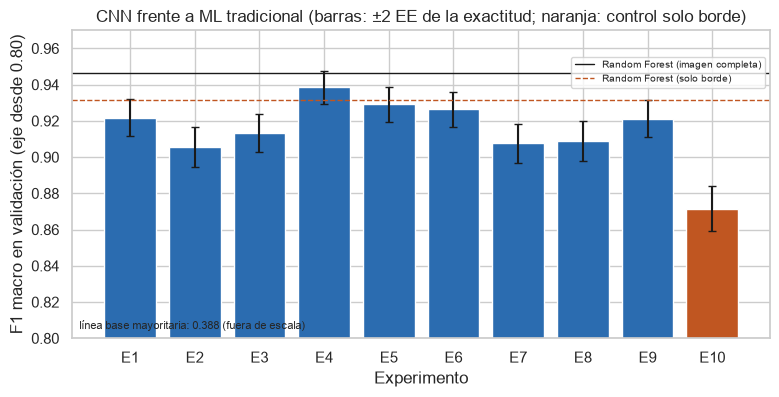

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
orden = res.sort_values("id", key=lambda s: s.str[1:].astype(int))
colores = ["#C05621" if b else "#2B6CB0" for b in orden["solo_borde"]]
ax.bar(orden["id"], orden["F1_val"], yerr=2 * orden["EE_val"], color=colores, capsize=3)
for nombre, estilo, etiqueta in [("random_forest", "-", "Random Forest (imagen completa)"), ("baseline_mayoritaria", ":", "línea base mayoritaria")]:
    ax.axhline(clasicos.loc[nombre, "F1_val"], color="k", ls=estilo, lw=1, label=etiqueta) if nombre != "baseline_mayoritaria" else None
ax.axhline(clasicos.loc["random_forest", "F1_val_borde"], color="#C05621", ls="--", lw=1, label="Random Forest (solo borde)")
ax.set_ylim(0.80, 0.97); ax.set_xlabel("Experimento"); ax.set_ylabel("F1 macro en validación (eje desde 0.80)")
ax.text(0.01, 0.03, f"línea base mayoritaria: {clasicos.loc['baseline_mayoritaria', 'F1_val']:.3f} (fuera de escala)", transform=ax.transAxes, fontsize=8)
ax.set_title("CNN frente a ML tradicional (barras: ±2 EE de la exactitud; naranja: control solo borde)")
ax.legend(fontsize=7, loc="upper right", bbox_to_anchor=(1.0, 0.93))
guardar(fig, "cnn_comparacion")
plt.show()

## 4. ¿Qué cambio importa? Diferencias entre experimentos con su significancia

Se compara cada par que difiere en **una sola cosa**. La diferencia de F1 se declara **no concluyente** si su valor absoluto
es menor que 2 veces el error estándar de la diferencia, `sqrt(EE_a² + EE_b²)` (criterio del curso). El EE es el de la
exactitud en validación, que se usa aquí como aproximación del error de muestreo del F1.

In [5]:
pares = [("E1", "E2", "Dropout 0.5 (con Flatten, Dense 64)"), ("E2", "E3", "GAP en lugar de Flatten (Dense 128 y Dropout 0.5)"),
         ("E3", "E5", "aumento de datos (GAP)"), ("E2", "E4", "aumento de datos (Flatten)"), ("E4", "E5", "GAP en lugar de Flatten (con aumento)"),
         ("E5", "E6", "L2 1e-4"), ("E5", "E7", "menos filtros (16-32-64)"), ("E5", "E8", "lr 3e-4 en lugar de 1e-3"),
         ("E5", "E9", "128 px en lugar de 96 px"), ("E5", "E10", "SOLO BORDE (centro enmascarado)")]
r = res.set_index("id")
filas = []
for a, b, que in pares:
    if a in r.index and b in r.index:
        d = r.loc[b, "F1_val"] - r.loc[a, "F1_val"]
        se = float(np.hypot(r.loc[a, "EE_val"], r.loc[b, "EE_val"]))
        filas.append({"cambio": f"{a} → {b}", "qué cambia": que, "ΔF1_val": d, "2·EE_dif": 2 * se,
                      "veredicto": "concluyente" if abs(d) >= 2 * se else "no concluyente"})
pd.DataFrame(filas).round(3)

,cambio,qué cambia,ΔF1_val,2·EE_dif,veredicto
0,E1 → E2,"Dropout 0.5 (con Flatten, Dense 64)",-0.016,0.015,concluyente
1,E2 → E3,GAP en lugar de Flatten (Dense 128 y Dropout 0.5),0.007,0.015,no concluyente
2,E3 → E5,aumento de datos (GAP),0.016,0.014,concluyente
3,E2 → E4,aumento de datos (Flatten),0.033,0.014,concluyente
4,E4 → E5,GAP en lugar de Flatten (con aumento),-0.009,0.013,no concluyente
5,E5 → E6,L2 1e-4,-0.003,0.014,no concluyente
6,E5 → E7,menos filtros (16-32-64),-0.022,0.015,concluyente
7,E5 → E8,lr 3e-4 en lugar de 1e-3,-0.020,0.015,concluyente
8,E5 → E9,128 px en lugar de 96 px,-0.008,0.014,no concluyente
9,E5 → E10,SOLO BORDE (centro enmascarado),-0.058,0.016,concluyente



**Lectura de los experimentos de calidad** (F1 macro en validación; error estándar de la exactitud ≈ 0.005; **una sola corrida por
experimento**, con la misma semilla).

1. **Mejor CNN: E4** (`Flatten`, Dropout 0.5, aumento de datos; 2 452 930 parámetros) con F1 0.938. **E5** (GAP, 110 018 parámetros,
   22 veces menos) llega a 0.929, y la diferencia **no es concluyente** (−0.009, menor que 2 EE). Con la misma calidad dentro del error,
   la versión con GAP es la preferible: es más pequeña, menos propensa a sobreajustar y liviana para la app.
2. **El aumento de datos ayuda** de forma concluyente: +0.033 con `Flatten` (E2 → E4) y +0.016 con GAP (E3 → E5).
3. **El Dropout 0.5 no ayudó con `Flatten` y Dense 64 sin aumento** (E1 → E2: −0.016, concluyente): redujo la brecha entre
   entrenamiento y validación (0.056 → 0.041) pero también el F1 de validación.
4. **`Flatten` frente a GAP no es concluyente** ni sin aumento (+0.007) ni con aumento (−0.009).
5. **L2 1e-4** (−0.003) y **128 px en lugar de 96 px** (−0.008) **no son concluyentes**, y 128 px cuesta más tiempo por época
   (59.4 s frente a 34.6 s). Menos filtros (−0.022) y una tasa de aprendizaje de 3e-4 (−0.020) **empeoran** de forma concluyente;
   en el segundo caso podría deberse a que la parada temprana (paciencia 3) cortó antes de converger, pero **no se probó**.
6. **Sobreajuste moderado:** la brecha de F1 entre entrenamiento y validación va de 0.017 (E3) a 0.056 (E1), y la parada temprana
   detuvo cada entrenamiento entre las épocas 5 y 18 (ver las curvas: la pérdida de validación se aplana y oscila mientras la de
   entrenamiento sigue bajando).
7. **La CNN no supera a ML tradicional en esta tarea.** El Random Forest sobre histogramas de color obtiene 0.947 frente a 0.938 de la
   mejor CNN (E4): diferencia de 0.008, menor que 2 EE, **no concluyente**. La SVM obtiene 0.944.
8. **Control "solo borde" (E10): el fondo explica casi todo.** Con el centro de la imagen enmascarado, la misma CNN alcanza **0.871**
   frente a 0.929 con la imagen completa (E5): ver la fruta aporta solo ~0.058 de F1 (concluyente). Es coherente con el Random Forest
   (0.931 solo con el borde) y con el EDA: **estas métricas de Kaggle no demuestran que se aprenda calidad**.

**Límites que se declaran:** (a) una sola semilla por experimento, así que diferencias de ~0.02 pueden incluir variación de la
inicialización que el error estándar de la validación no captura; (b) la validación se usó para la parada temprana y para elegir,
por lo que es **optimista**; (c) tarea binaria con etiquetas débiles de Kaggle; (d) el test **no se usó**.


## 5. Clasificador de especie (6 clases)

In [6]:
esp = pd.read_csv(REPO / "04_modelado" / "resultados_cnn_especie.csv")
esp[["id", "descripcion", "F1_val", "exactitud_val", "EE_val", "kappa_val", "epocas_corridas", "parametros"]].round(3)

,id,descripcion,F1_val,exactitud_val,EE_val,kappa_val,epocas_corridas,parametros
0,RF_full,"Random Forest sobre color, región full",0.908,0.927,0.005,0.917,NaN,NaN
1,RF_border,"Random Forest sobre color, región border",0.800,0.829,0.007,0.787,NaN,NaN
2,S1,Especie: GAP + Dropout 0.5 + aumento de datos,0.790,0.833,0.007,0.835,9.0,110534.0
3,S2,CONTROL solo borde (especie): centro enmascarado,0.658,0.712,0.009,0.658,17.0,110534.0


In [7]:
por_especie = {}
for ident in ("S1", "S2"):
    ruta = PROC / f"especie_{ident}.json"
    if ruta.exists():
        d = json.loads(ruta.read_text(encoding="utf-8"))["por_especie"]
        por_especie[f"CNN {ident}"] = {k: v["exactitud"] for k, v in d.items()}
pd.DataFrame(por_especie).round(3).rename_axis("especie")

,CNN S1,CNN S2
especie,,
apple,0.762,0.563
banana,0.994,0.781
guava,0.666,0.540
lime,0.811,0.740
orange,0.644,0.500
pomegranate,0.928,0.856



**Lectura del clasificador de especie** (6 clases; F1 macro en validación; el azar daría ≈ 0.17).

* **La CNN pequeña (S1) rinde peor que un Random Forest sobre color:** F1 0.790 frente a 0.908 (RF con la imagen completa). La CNN
  se detuvo en la época 9 y **no se ajustó** (se probó una sola configuración), así que no se puede afirmar que una CNN no sirva
  para esta tarea; solo que esta no superó al modelo de color.
* **El fondo identifica la especie:** con solo el borde, el Random Forest llega a 0.800 y la CNN (S2) a 0.658, muy por encima del
  azar. Cada especie se fotografió en entornos distintos, así que un clasificador entrenado con este dataset **aprende en parte el
  entorno y no la fruta**.
* **Por especie (exactitud de la CNN S1):** banano 0.994, granada 0.928, lima 0.811, manzana 0.762, guayaba 0.666, naranja 0.644.
* **Consecuencia para la app:** no se debe afirmar una exactitud de especie a partir de Kaggle. La especie debería elegirla la persona
  o validarse en las fotos propias antes de usarla. Sirve, eso sí, para la prueba de atajos y para segmentar el tamaño por especie.
